# Del texto a tu voz · un reel con modelos abiertos

Un texto largo se convierte en un reel vertical de unos 50 segundos, narrado con **tu voz clonada**, con subtítulos y listo
para Facebook, X o LinkedIn. Todo corre en tu laptop con modelos abiertos: tu voz no sale a ninguna API.

| Paso | Qué hace | Modelo |
|---|---|---|
| 1 | Texto → guion por escenas y posts | Qwen3.8-27B (Alibaba) o el chat que prefieran |
| 2 | Revisar el guion contra la fuente | ustedes |
| 3 | Guion → narración con tu voz | Qwen3-TTS (Alibaba, Apache 2.0) |
| 4 | Narración → subtítulos y control de calidad | Whisper large-v3-turbo (OpenAI, MIT) |
| 5 | Video 1080×1920 con cifras y subtítulos | Pillow + ffmpeg |
| 6 | Opcional: voz de locutor con estilo por escena | VoxCPM2 (OpenBMB, Apache 2.0) |

![Cuatro cuadros de un reel](figuras/reel_cuadros.png)

**Reglas:** clonen solo su propia voz; el video y los posts dicen «Voz generada con IA»; nada se publica sin leer el guion
completo contra la fuente.

### Antes de empezar (una vez, en la terminal)

```bash
cd sessions/15-texto-a-reel
uv venv .venv
uv pip install --python .venv/bin/python qwen-tts faster-whisper pillow imageio-ffmpeg soundfile jiwer num2words pypdf \
    pandas matplotlib librosa jupyterlab
uv pip install --python .venv/bin/python voxcpm      # opcional, para la sección 6
.venv/bin/jupyter lab texto_a_reel.ipynb
```

En Windows la ruta es `.venv\Scripts\python` y `.venv\Scripts\jupyter`. Va en un entorno propio porque `qwen-tts` fija
`transformers==4.57.3`. La primera corrida baja de 4 a 6 GB de modelos (la voz y Whisper); VoxCPM2 suma otros 4.6 GB.

Graben 10 a 25 segundos de su voz (una nota de voz de WhatsApp sirve) y guárdenla en esta carpeta como `mi_voz.opus`,
`mi_voz.m4a` o `mi_voz.wav`. Git la ignora, igual que la carpeta `salidas_notebook/`.

In [1]:
import json, os, time, urllib.request, warnings
from pathlib import Path
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"         # sin barras de avance de VoxCPM2
warnings.filterwarnings("ignore")
from transformers.utils import logging; logging.set_verbosity_error()
import numpy as np, pandas as pd, matplotlib.pyplot as plt, soundfile as sf, torch
from IPython.display import Audio, Video, display
pd.set_option("display.max_colwidth", 140)

SESION = Path.cwd()
import guion as g      # paso 1: texto -> guion
import reel            # pasos 3 a 5: voz, subtítulos y video

# Lo que cambia cada uno
VOZ = SESION / "mi_voz.opus"      # 10 a 25 s de su voz: .opus de WhatsApp, .m4a, .ogg o .wav
AUTOR = "Alexander Quispe"
FUENTE = "NASA FIRMS, INPE, SERNANP · incendios-peru"    # aparece al pie del video
TEXTO = None                       # su .pdf, .md o .txt; None = README del monitor de incendios
INCRUSTAR = False                  # True en VS Code: el audio y el video quedan dentro del notebook (no lo suban así)

DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
TTS = reel.TTS if DEVICE != "cpu" else "Qwen/Qwen3-TTS-12Hz-0.6B-Base"   # en CPU, el modelo chico
SALIDAS = SESION / "salidas_notebook"     # no se versiona: aquí quedan su voz y su video
SALIDAS.mkdir(exist_ok=True)


def escuchar(w, nombre, sr):
    # Guarda el audio en SALIDAS; sin INCRUSTAR, el notebook guarda solo el enlace y no su voz
    ruta = SALIDAS / nombre
    sf.write(ruta, np.asarray(w, np.float32), sr)
    return Audio(filename=ruta) if INCRUSTAR else Audio(url=ruta.relative_to(SESION).as_posix())


print(f"Dispositivo: {DEVICE} · voz: {TTS.split('/')[-1]} · {VOZ.name}: {'ok' if VOZ.exists() else 'NO EXISTE'}")

Dispositivo: mps · voz: Qwen3-TTS-12Hz-1.7B-Base · mi_voz.opus: ok


## 1 · Del texto al guion

Un modelo de lenguaje resume el texto en 5 a 7 **escenas**. Cada escena tiene tres partes:

- `frase`: lo que dice la voz, con los números **en palabras** («ciento veintiséis por ciento»), para que la voz no lea mal «126 %».
- `cifra`: lo que se ve en pantalla, con dígitos (`+126 %`).
- `etiqueta`: qué significa la cifra, en 3 a 8 palabras.

El ejemplo es el README del [monitor de incendios del Perú](https://github.com/alexanderquispe/incendios-peru), fijado en la
versión del 22 de octubre de 2026 para que las cifras no cambien. `g.leer` también lee PDF.

In [2]:
EJEMPLO = ("https://raw.githubusercontent.com/alexanderquispe/incendios-peru/"
           "4665147d54f246e30c9035fa1814f43a8dc08894/README.md")
ES_EJEMPLO = TEXTO is None
ruta_texto = SALIDAS / "incendios_peru.md" if ES_EJEMPLO else Path(TEXTO)
if ES_EJEMPLO and not ruta_texto.exists():
    urllib.request.urlretrieve(EJEMPLO, ruta_texto)

texto = g.leer(ruta_texto)
print(f"{len(texto.split()):,} palabras\n")
print(texto[:900])

2,023 palabras

# Monitor de Incendios Forestales del Perú

Tablero de situación de la temporada de incendios 2026 construido con datos satelitales públicos.
Inspirado en el prototipo de análisis de incendios de [@DilumSanjaya](https://x.com/DilumSanjaya/status/2108241054298415258),
que usaba terreno procedural y datos simulados. Esta versión usa datos reales del Perú: focos VIIRS, relieve real, imágenes
Sentinel-2 y límites oficiales.

**Sitio web:** https://alexanderquispe.github.io/incendios-peru/ (GitHub Pages; se publica solo con cada cambio en `main`, ver `.github/workflows/pages.yml` y `src/sitio.py`). El pie del sitio muestra un contador de visitas (una por sesión del navegador, servicio abierto [Abacus](https://abacus.jasoncameron.dev), sin cookies) que no aparece en el Artifact. También está en https://claude.ai/artifact/UsyGgMV7ysFBEDzzrW5DeU.

**Repositorio:** https://github.com/alexanderqui


### El prompt

Qwen3.8-27B solo corre en una Mac con 32 GB de RAM, así que en clase usamos un chat gratuito con **el mismo prompt**. Tres
reglas del prompt fueron las que más mejoraron el guion: los números en palabras para la voz y en dígitos para la pantalla,
la fecha de corte de los datos y prohibir etiquetas como «gancho» o «invitación», que el modelo ponía en pantalla.

In [3]:
msgs = g.mensajes(texto, segundos=50)
prompt = msgs[0]["content"] + "\n\n" + msgs[1]["content"]
(SALIDAS / "prompt.txt").write_text(prompt, encoding="utf-8")
print(f"salidas_notebook/prompt.txt: {len(prompt):,} caracteres. Las instrucciones, sin el texto fuente:\n")
print(prompt[prompt.find(">>>") + 4:])

salidas_notebook/prompt.txt: 14,936 caracteres. Las instrucciones, sin el texto fuente:


Escribe el guion de un reel de 50 segundos (unas 125 palabras en total) en español del Perú,
narrado en primera persona por el autor del texto.

Reglas:
- Entre 5 y 7 escenas. La primera es un gancho; la última cierra con una invitación (ver el tablero, comentar).
- Cada escena tiene una sola idea y como máximo una cifra.
- Usa solo cifras que estén en el texto fuente. No redondees, no inventes y no exageres.
- Si el texto tiene una fecha de corte de los datos, dila en la primera o segunda escena.
- "frase": lo que se dice en voz alta, de 15 a 25 palabras, y debe decir la cifra de su escena.
  No uses dígitos en las frases: escribe todos los números en palabras, también los años
  (por ejemplo "ciento veintiséis por ciento", "dos mil doce").
- "cifra": lo que se ve en pantalla, muy corto, con dígitos (por ejemplo "+126 %", "56", "12,984"). Puede ir vacío.
- "etiqueta": de 3 a 8 palabras que explic

1. Abran `salidas_notebook/prompt.txt`, copien todo y péguenlo en [chat.qwen.ai](https://chat.qwen.ai),
   [chat.deepseek.com](https://chat.deepseek.com) o [claude.ai](https://claude.ai).
2. Guarden la respuesta completa en `salidas_notebook/respuesta.txt`.
3. Corran la celda de abajo. `g.a_guion` saca el JSON de la respuesta y busca cada cifra en el texto fuente.

Sin `respuesta.txt`, se usa el guion de ejemplo, que ya revisamos a mano.

In [4]:
respuesta = SALIDAS / "respuesta.txt"
if respuesta.exists():
    crudo = respuesta.read_text(encoding="utf-8")
elif ES_EJEMPLO:
    crudo = (SESION / "ejemplo" / "guion_incendios.json").read_text(encoding="utf-8")
else:
    raise FileNotFoundError(f"Peguen la respuesta del chat en {respuesta}")

guion = g.a_guion(crudo, texto)
for e in guion["escenas"]:
    e.pop("wer", None)      # el WER se mide de nuevo con su voz

escenas = pd.DataFrame(guion["escenas"])
escenas["palabras"] = escenas.frase.str.split().str.len()
print(f"«{guion['titulo']}»: {len(escenas)} escenas, {escenas.palabras.sum()} palabras "
      f"≈ {escenas.palabras.sum() / 2.5:.0f} s a 2.5 palabras por segundo")
escenas[["cifra", "etiqueta", "cifra_en_texto", "palabras", "frase"]]

«Perú en llamas 2026»: 6 escenas, 120 palabras ≈ 48 s a 2.5 palabras por segundo


,cifra,etiqueta,cifra_en_texto,palabras,frase
0,17 oct 2026,Fecha de corte de datos,True,20,"Al corte del diecisiete de octubre de dos mil veintiséis, los datos satelitales muestran una realidad crítica en nuestro territorio."
1,"12,984",Focos S-NPP en octubre,True,20,"Octubre es el más intenso desde dos mil doce, con doce mil novecientos ochenta y cuatro focos detectados por satélite."
2,+126 %,Crecimiento vs promedio 2012-2025,True,19,Esta cifra representa un aumento del ciento veintiséis por ciento sobre el promedio histórico de los últimos catorce años.
3,56,Incendios activos > 100 ha,True,24,Cincuenta y seis incendios activos superan las cien hectáreas; el de Río Tambo arde a ocho punto siete kilómetros de la Reserva Comunal ...
4,28,ANP con focos en 7 días,True,17,"Veintiocho áreas naturales protegidas registran focos de calor, amenazando ecosistemas únicos de la selva y la sierra."
5,,Mira el tablero: enlace en mi perfil,True,20,Construí este tablero con datos abiertos para entender la crisis; te invito a explorar el análisis completo en mi perfil.


## 2 · Revisar el guion: la parte que no se automatiza

La verificación compara números sin separadores de miles: «12,984» y «12984» cuentan igual.

In [5]:
print(g._numeros("12,984 focos, +126 % y 8.7 km"))

# Un guion que exagera: una cifra de pantalla y otra en el post de X que no están en el texto
exagerado = json.loads(json.dumps(guion))
exagerado["escenas"][2]["cifra"] = "+140 %"
exagerado["posts"]["x"] += " Ya son más de 20,000 focos."
r = g.a_guion(json.dumps(exagerado, ensure_ascii=False), texto)
print("¿Cada cifra está en el texto?", [e["cifra_en_texto"] for e in r["escenas"]])
print("Cifras de los posts que no están en el texto:", r["cifras_dudosas_en_posts"])

{'8.7', '126', '12984'}
¿Cada cifra está en el texto? [True, True, False, True, True, True]
Cifras de los posts que no están en el texto: ['20000']


**Lo que la verificación no ve:** las cifras pueden estar bien y la frase ser falsa. En un borrador, Qwen escribió que los
incendios estaban «afectando» la Reserva Comunal Asháninka. El texto dice otra cosa:

In [6]:
def buscar(palabra):
    # Los párrafos del texto fuente que mencionan una palabra: así se revisa cada frase
    for p in texto.split("\n\n"):
        if palabra.lower() in p.lower():
            print("·", " ".join(p.split()), "\n")


buscar("Asháninka")       # cambien la palabra para revisar su propio guion
print([e["revisado_a_mano"] for e in guion["escenas"] if "revisado_a_mano" in e])

· - **Octubre es el más intenso desde 2012**: 12,984 focos S-NPP entre el 1 y el 16 de octubre, +126 % sobre el promedio 2012–2025 y por encima del récord previo (2020: 11,776). - **Temporada tardía**: del 1 de julio al 16 de octubre el acumulado va 17 % por debajo del promedio (puesto 12 de 15); julio, agosto y setiembre quedaron bajo el promedio. - 56 incendios activos con huella mayor a 100 ha; 2,812 focos en 24 h (9 % menos que las 24 h previas) y 13,915 en 7 días. - Los que más se extendieron en 24 h: Manantay (Ucayali, +492 ha de huella), San Juan de Jarpa (Junín) y Chichas (Arequipa, +422 ha cada uno). - Los incendios activos más extensos están en Curahuasi y San Pedro de Cachora (Abancay, Apurímac) y en Río Tambo (Satipo, Junín), a 8.7 km de la Reserva Comunal Asháninka. - 28 áreas naturales protegidas con focos en 7 días (Imiria, Pacaya-Samiria y Subcuenca del Cotahuasi, las más afectadas). - Validación: se detectaron los incendios reportados en Río Tambo, Huascarán–Llanganuco

Antes de seguir, lean cada `frase` contra la fuente:

- ¿La cifra dice lo mismo que el texto: el mismo periodo, la misma unidad, la misma comparación?
- ¿Hay palabras que exageran? Otros borradores dijeron «fuera de control» y «en tiempo real».
- ¿Se dice la fecha de corte de los datos?
- ¿La etiqueta se entiende sin audio? Muchos ven los reels en silencio.

Corrijan aquí, por ejemplo `guion["escenas"][3]["frase"] = "..."`, o en `respuesta.txt`, y anoten en su README qué cambiaron.

## 3 · Tu voz

### La grabación de referencia

El clon copia todo de la grabación: el tono, la energía, y también el ruido y la saturación. `reel.cargar_audio` usa ffmpeg,
así que lee las notas de voz de WhatsApp.

25.5 s · pico 1.00 · 0.004% de muestras saturadas


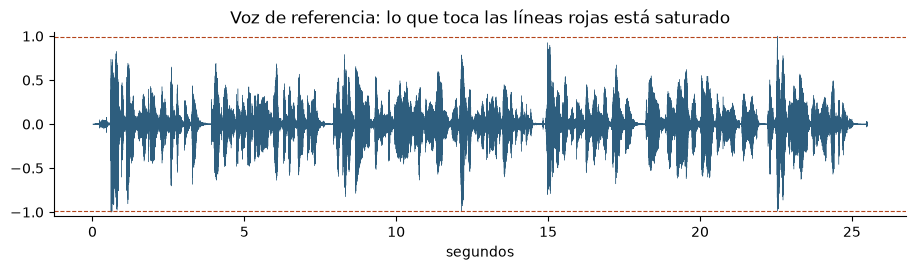

In [7]:
ref = reel.cargar_audio(VOZ)          # mono, 16 kHz, float32
saturadas = np.mean(np.abs(ref) > 0.99)
print(f"{len(ref) / 16000:.1f} s · pico {np.abs(ref).max():.2f} · {saturadas:.3%} de muestras saturadas")

fig, ax = plt.subplots(figsize=(11, 2.4))
ax.plot(np.arange(len(ref)) / 16000, ref, lw=0.3, color="#2E5E7E")
for y in (-0.99, 0.99):
    ax.axhline(y, color="#B4441A", lw=0.8, ls="--")
ax.set(xlabel="segundos", ylim=(-1.05, 1.05), title="Voz de referencia: lo que toca las líneas rojas está saturado")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(SALIDAS / "referencia.png", dpi=150, bbox_inches="tight")
plt.show()
escuchar(ref, "referencia.wav", 16000)

Si más del 0.1 % de las muestras están saturadas, o la grabación dura menos de 10 s, graben de nuevo: en un cuarto callado,
a un palmo del micrófono y con el tono que quieren en el reel.

### Clonar con Qwen3-TTS

Qwen3-TTS necesita el audio **y lo que dice**. Whisper lo transcribe; con los dos, el modelo arma un *prompt de voz* que se
reutiliza en cada frase. En CPU usamos el modelo de 0.6B; con GPU o una Mac con chip M, el de 1.7B. Los avisos de SoX y de
flash-attn al cargar no importan: el audio se lee con ffmpeg y flash-attn solo sirve en GPU NVIDIA.

In [8]:
t = time.time()
voz = reel.Voz(VOZ, modelo=TTS, device=DEVICE)
print(f"Cargado en {time.time() - t:.0f} s. Whisper oyó en la referencia:\n«{voz.texto_ref}»")

/bin/sh: sox: command not found
SoX could not be found!

    If you do not have SoX, proceed here:
     - - - http://sox.sourceforge.net/ - - -

    If you do (or think that you should) have SoX, double-check your
    path variables.
    



********
********
 


[WARNING] Min value of input waveform signal is -1.00081467628479
[WARNING] Max value of input waveform signal is 1.0027906894683838
Cargado en 13 s. Whisper oyó en la referencia:
«Hola, ¿qué tal? Mi nombre es Alexander Kispe. Yo soy un profesor de la Universidad Católica del Perú y he trabajado como investigador en el Banco Mundial, en Harvard y en el Tecnológico de Massachusetts. Ahora mismo estoy dictando una clase de ciencia de datos para alumnos en la Escuela de Graduados de la Universidad Católica.»


Whisper se equivoca con los nombres propios. Como Qwen3-TTS solo usa ese texto para alinear la voz, un error así casi no
afecta al clon.

### Una frase

Si una frase tarda más en generarse de lo que dura, la laptop va a tardar en todo el guion: con el modelo de 0.6B en
CPU, multipliquen la duración del reel por 1.5 a 3.

In [9]:
frase = guion["escenas"][1]["frase"]
t = time.time()
w = voz.decir([frase])[0]
gen, dur = time.time() - t, len(w) / voz.sr
print(f"{dur:.1f} s de audio en {gen:.1f} s (x{gen / dur:.2f}) a {voz.sr:,} Hz\n«{frase}»")
escuchar(w, "una_frase.wav", voz.sr)

8.6 s de audio en 8.6 s (x1.00) a 24,000 Hz
«Octubre es el más intenso desde dos mil doce, con doce mil novecientos ochenta y cuatro focos detectados por satélite.»


### ¿Se entiende? El WER

Para no escuchar cada versión, Whisper transcribe lo que dijo la voz clonada y lo comparamos con el guion. El **WER** (*word
error rate*) es la proporción de palabras que hay que cambiar, borrar o añadir para llegar del guion a lo que se oyó: 0 es
perfecto. Antes hay que normalizar, porque Whisper escribe «12,984» donde el guion dice «doce mil novecientos ochenta y
cuatro».

In [10]:
import jiwer
oido = " ".join(s.text.strip() for s in reel._whisper().transcribe(reel._a16k(w, voz.sr), language="es")[0])
print("Guion:  ", frase)
print("Whisper:", oido)
print("\nNormalizado:", reel._normalizar(oido))
print(f"\nWER sin normalizar: {jiwer.wer(frase.lower(), oido.lower()):.2f}")
print(f"WER normalizado:    {jiwer.wer(reel._normalizar(frase), reel._normalizar(oido)):.2f}")

Guion:   Octubre es el más intenso desde dos mil doce, con doce mil novecientos ochenta y cuatro focos detectados por satélite.
Whisper: Octubre es el más intenso desde 2012 con 12.984 focos detectados por satélite.

Normalizado: octubre es el mas intenso desde dos mil doce con doce mil novecientos ochenta y cuatro focos detectados por satelite

WER sin normalizar: 0.45
WER normalizado:    0.00


### Todo el guion

`reel.narrar` dice cada escena, mide su WER y vuelve a generar las que pasan de 0.25: los modelos de voz a veces se saltan o
repiten palabras. Luego une las escenas con 0.35 s de silencio y guarda cuándo empieza y termina cada una.

In [11]:
t = time.time()
narracion = reel.narrar(voz, guion)
print(f"{narracion.duracion:.1f} s de narración en {time.time() - t:.0f} s")
display(pd.DataFrame([{"inicio": a, "fin": b, "wer": e["wer"], "frase": e["frase"]}
                      for e, (a, b) in zip(guion["escenas"], narracion.escenas)]).round(2))
escuchar(narracion.audio, "narracion.wav", narracion.sr)

58.9 s de narración en 45 s


,inicio,fin,wer,frase
0,0.30,9.58,0.00,"Al corte del diecisiete de octubre de dos mil veintiséis, los datos satelitales muestran una realidad crítica en nuestro territorio."
1,9.93,19.13,0.00,"Octubre es el más intenso desde dos mil doce, con doce mil novecientos ochenta y cuatro focos detectados por satélite."
2,19.48,27.96,0.00,Esta cifra representa un aumento del ciento veintiséis por ciento sobre el promedio histórico de los últimos catorce años.
3,28.31,39.83,0.08,Cincuenta y seis incendios activos superan las cien hectáreas; el de Río Tambo arde a ocho punto siete kilómetros de la Reserva Comunal ...
4,40.18,48.74,0.00,"Veintiocho áreas naturales protegidas registran focos de calor, amenazando ecosistemas únicos de la selva y la sierra."
5,49.09,57.73,0.00,Construí este tablero con datos abiertos para entender la crisis; te invito a explorar el análisis completo en mi perfil.


## 4 · Subtítulos palabra por palabra

Whisper también da el tiempo de cada palabra. Le pasamos el guion como contexto (`initial_prompt`) para que escriba bien
los nombres propios, y pegamos los pedazos que corta mal: «8» y «.7» vuelven a ser «8.7».

In [12]:
palabras = reel.subtitulos(narracion, guion)
print(f"{len(palabras)} palabras")
pd.DataFrame(palabras[:10], columns=["inicio", "fin", "palabra"]).round(2)

125 palabras


,inicio,fin,palabra
0,0.00,1.04,Al
1,1.04,1.48,corte
2,1.48,1.64,del
3,1.64,2.10,diecisiete
4,2.10,2.28,de
5,2.28,2.72,octubre
6,2.72,2.94,de
7,2.94,3.12,dos
8,3.12,3.26,mil
9,3.26,3.92,"veintiséis,"


En el celular se leen bloques de hasta 4 palabras o 24 letras, cortados en los signos de puntuación. El mismo corte va al
archivo `.srt`, que LinkedIn y Facebook aceptan como subtítulos aparte.

In [13]:
for b in reel._bloques(palabras)[:8]:
    print(f"{b[0][0]:5.2f} → {b[-1][1]:5.2f}   {' '.join(p[2] for p in b)}")
reel.a_srt(narracion, SALIDAS / "reel.srt")
print("\n" + (SALIDAS / "reel.srt").read_text(encoding="utf-8")[:160])

 0.00 →  2.10   Al corte del diecisiete
 2.10 →  3.12   de octubre de dos
 3.12 →  3.92   mil veintiséis,
 4.22 →  6.54   los datos satelitales muestran
 6.54 →  8.30   una realidad crítica en
 8.30 →  9.38   nuestro territorio.
10.64 → 12.34   Octubre es el más
12.34 → 13.70   intenso desde dos mil

1
00:00:00,000 --> 00:00:02,100
Al corte del diecisiete

2
00:00:02,100 --> 00:00:03,120
de octubre de dos

3
00:00:03,120 --> 00:00:03,919
mil veintiséis,

4
0


## 5 · El video

Pillow dibuja cada cuadro y ffmpeg lo convierte en MP4: 30 cuadros por segundo a 1080×1920. Cada cuadro junta cuatro capas:

1. `reel._base`: lo que no cambia, que es el título, el aviso «Voz generada con IA» y la fuente.
2. `reel._escena`: la cifra grande y su etiqueta, que entra suave en 0.35 s.
3. La barra de avance arriba, como en las historias.
4. El subtítulo, con la palabra que se está diciendo en naranja.

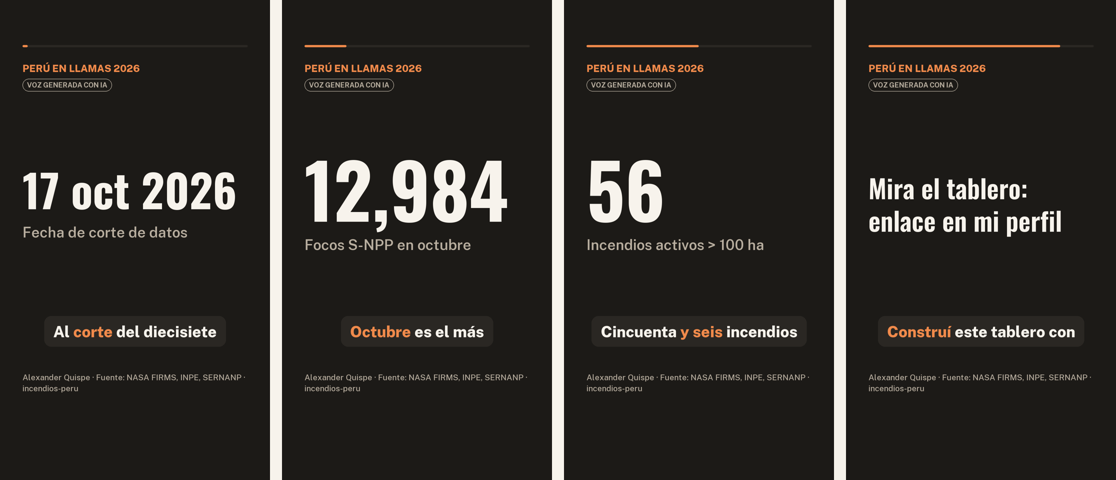

In [14]:
from PIL import Image
base = reel._base(guion["titulo"], FUENTE, AUTOR)
capas = [reel._escena(e) for e in guion["escenas"]]
bloques = reel._bloques(narracion.palabras)
fuente_sub = reel._fuente("PublicSans", 62, 800)

# un cuadro un segundo después del inicio de cuatro escenas
elegidas = [0, 1, 3, len(capas) - 1]
cuadros = [reel._cuadro(base, capas, narracion, narracion.escenas[i][0] + 1.0, bloques, fuente_sub) for i in elegidas]
tira = Image.new("RGB", (4 * 540 + 3 * 24, 960), "#F7F3EC")
for k, c in enumerate(cuadros):
    tira.paste(c.resize((540, 960)), (k * (540 + 24), 0))
tira.save(SALIDAS / "cuadros.png")
tira.resize((tira.width // 2, tira.height // 2))

Un reel de 50 s son 1,500 cuadros. ffmpeg además normaliza el volumen a −14 LUFS, el nivel que usan Instagram y TikTok,
para que su voz no suene más baja que el reel anterior.

In [15]:
t = time.time()
mp4 = reel.video(guion, narracion, SALIDAS / "reel.mp4", FUENTE, AUTOR)
reel.portada(guion, narracion, SALIDAS / "portada.png", FUENTE, AUTOR)
(SALIDAS / "guion.json").write_text(json.dumps(guion, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"{mp4.name}: {mp4.stat().st_size / 1e6:.1f} MB, {narracion.duracion:.0f} s, en {time.time() - t:.0f} s")
Video(mp4, embed=True, width=360) if INCRUSTAR else Video(mp4.relative_to(SESION).as_posix(), width=360)

reel.mp4: 2.4 MB, 59 s, en 7 s


### Los posts

El mismo guion trae un post para cada red, que también termina con el aviso de voz generada con IA. X corta en 280
caracteres.

In [16]:
reel.posts(guion, SALIDAS / "posts.md")
for red, post in guion["posts"].items():
    print(f"── {red} ({len(post)} caracteres)\n{post}\n")
print(" ".join(guion["hashtags"]))

── linkedin (309 caracteres)
La temporada de incendios 2026 en Perú está marcando récords históricos. 

Construí un tablero interactivo con datos satelitales reales (VIIRS, Sentinel-2) para visualizar la magnitud de la crisis. 

Octubre supera en un 126% el promedio histórico. La voz de este video fue generada con IA a partir de mi voz.

── x (219 caracteres)
Octubre 2026: 12,984 focos de calor en Perú. +126% vs promedio histórico. 

Creé un tablero con datos satelitales reales para analizar la crisis. 

Enlace al tablero en mi bio. 

(Voz generada con IA a partir de mi voz)

── facebook (234 caracteres)
El fuego avanza en el Perú. Este año, octubre es el más intenso desde 2012. 

Desarrollé una herramienta con datos abiertos para monitorear la situación en tiempo real. 

Comparte este video. 

(Voz generada con IA a partir de mi voz)

#IncendiosPeru #DataScience #CrisisClimatica #Amazonia #DatosAbiertos


Los posts también se revisan contra la fuente. El tablero no es en tiempo real: se actualiza cuando se corre
`src/actualizar.py`, que tarda unos 45 minutos. Y en octubre se superó **un** récord, el de 2020:

In [17]:
for palabra in ["tiempo real", "fuera de control", "récords"]:
    for red, post in guion["posts"].items():
        if palabra in post.lower():
            print(f"{red}: «{palabra}»")

facebook: «tiempo real»
linkedin: «récords»


Ejercicio: corrijan esos dos posts en `guion["posts"]` y vuelvan a correr `reel.posts`.

## 6 · Opcional: voz de locutor con VoxCPM2

VoxCPM2 (OpenBMB, Apache 2.0) también clona la voz y además acepta un **estilo** entre paréntesis antes de cada frase.
`reel.ESTILOS` pone uno para la primera escena, otro para las del medio y otro para el cierre; en inglés funcionan mejor que
en español. Una escena puede traer su propio `"estilo"` en el guion.

Usa otros 4.6 GB de memoria; por eso primero soltamos Qwen3-TTS. En CPU no lo medimos: pruébenlo en casa.

In [18]:
reel.ESTILOS

{'inicio': 'urgent, dramatic news anchor, strong emphasis',
 'medio': 'confident news anchor, energetic, clear emphasis on the numbers',
 'cierre': 'warm, friendly, inviting tone'}

In [19]:
import gc
from pruebas.comparar_voces import prosodia

PROBAR_VOXCPM = DEVICE != "cpu"
if PROBAR_VOXCPM:
    del voz
    gc.collect()
    t = time.time()
    locutor = reel.VozExpresiva(VOZ, device=DEVICE)
    guion_locutor = json.loads(json.dumps(guion))
    narracion_locutor = reel.narrar(locutor, guion_locutor, velocidad=1.08)   # 8 % más rápido, sin cambiar el tono
    print(f"{narracion_locutor.duracion:.1f} s de narración en {time.time() - t:.0f} s, con la carga del modelo")

    n = sum(len(e["frase"].split()) for e in guion["escenas"])
    display(pd.DataFrame({"Qwen3-TTS": prosodia(narracion.audio, narracion.sr, n),
                          "VoxCPM2 locutor": prosodia(narracion_locutor.audio, narracion_locutor.sr, n)}).T.round(2))

voxcpm_model_path: /Users/alexanderquispe/.cache/huggingface/hub/models--openbmb--VoxCPM2/snapshots/32279effe8c19989596f05d353d1447f51d9e915, zipenhancer_model_path: None, enable_denoiser: False
Loading AudioVAE from pytorch: /Users/alexanderquispe/.cache/huggingface/hub/models--openbmb--VoxCPM2/snapshots/32279effe8c19989596f05d353d1447f51d9e915/audiovae.pth


[voxcpm2] adjusted dtype bfloat16 -> float32 for device mps
Running on device: mps, dtype: float32


Loading model from safetensors: /Users/alexanderquispe/.cache/huggingface/hub/models--openbmb--VoxCPM2/snapshots/32279effe8c19989596f05d353d1447f51d9e915/model.safetensors


Loaded VoxCPM2Model


45.1 s de narración en 76 s, con la carga del modelo


,duracion_s,palabras_s,desvio_st,rango_st,sr
Qwen3-TTS,58.88,2.38,2.89,6.60,24000.0
VoxCPM2 locutor,45.13,2.96,2.55,8.29,48000.0


`palabras_s` es el ritmo al hablar, sin contar silencios. `desvio_st` y `rango_st` miden cuánto sube y baja el tono, en
semitonos. Escuchen las dos: más entonación no siempre suena mejor. En nuestras pruebas, lo estable fue el ritmo (unas 2.5
frente a 3.0 palabras por segundo); la entonación cambió de una corrida a otra, el efecto del estilo entre paréntesis no fue
concluyente y lo que más cambió la narración fue cómo se grabó la referencia.

In [20]:
if PROBAR_VOXCPM:
    display(escuchar(narracion.audio, "narracion.wav", narracion.sr),
            escuchar(narracion_locutor.audio, "narracion_locutor.wav", narracion_locutor.sr))

Para el reel completo con esta voz, desde la terminal:

```bash
.venv/bin/python hacer_reel.py --voz mi_voz.opus --autor "Su nombre" --fuente "Su fuente" \
    --motor voxcpm --velocidad 1.08 --device mps --salidas salidas_notebook
```

`hacer_reel.py` lee `salidas_notebook/guion.json`, el que guardó la sección 5, y deja ahí `reel.mp4`.

## 7 · Su turno (45 minutos)

1. Elijan un texto con cifras: un informe, una sentencia, un plan de gobierno o su propio trabajo. Pongan su ruta en `TEXTO`.
2. Generen el prompt, péguenlo en un chat y guarden la respuesta en `salidas_notebook/respuesta.txt`.
3. Revisen cada frase contra la fuente y anoten qué corrigieron.
4. Graben su voz, cambien `VOZ`, `AUTOR` y `FUENTE`, y corran todo el notebook (*Run → Run All Cells*).
5. Suban a un repo suyo el `reel.mp4`, el `posts.md` y un README con lo que corrigieron. Si no quieren que su voz quede
   pública, suban solo el guion y los posts.
6. Peguen el link del repo en el [issue #196](https://github.com/d2cml-ai/Data-Science-Python/issues/196).

Al final elegimos a tres al azar: cada uno pasa su reel y cuenta qué tuvo que corregir del guion.